In [10]:
# data handling
import pandas as pd
import numpy as np

#visualization
import matplotlib.pyplot as plt
import seaborn as sns

In [11]:
#statistical libraries
from scipy import stats
import statsmodels.api as sm

In [12]:
#python to postgresql connection
from sqlalchemy import create_engine
import psycopg2

In [13]:
#visulaize missing data
import missingno as msno

In [14]:
#loading files
bank=pd.read_csv(r"C:/Users/rakhi/OneDrive/Desktop/Data project/BFSI/bank_data.csv")
customer= pd.read_csv(r"C:/Users/rakhi/OneDrive/Desktop/Data project/BFSI/customer_data.csv")
transaction= pd.read_csv(r"C:/Users/rakhi/OneDrive/Desktop/Data project/BFSI/transaction_data.csv")

In [15]:
dfs ={
    'bank': bank,
    'customer':customer,
    'transaction': transaction,
}
for name,df in dfs.items():
    print(f"\n{'='*10}")
    print(f"{name}")

    print(f"{'='*10}")
    print("overview")
    print(df.head())
    
    print(f"\n{'shape:'}")
    print(df.shape)

    print(f"\n{'='*10}")
    print("info")
    print(df.info())

    print(f"\n{'='*10}")
    print("describe")
    print(df.describe())
    
    

    print(f"\n{'='*10}")
    print("missing values")
    print(df.isnull().sum())

    print(f"\n{'='*10}")
    print('duplicate values')
    print(df.duplicated().sum())


bank
overview
   Branch_ID     City Region  Firm_Revenue  Expenses  Profit_Margin
0       1000  Solapur   East      422443.0    346471          56.31
1       1001   Mumbai  North      211155.0    216256          79.53
2       1002   Nashik   West      985006.0     71777          55.31
3       1003  Solapur  North       55113.0    253655           2.57
4       1004   Nagpur   West      282701.0    148194         -14.10

shape:
(1000, 6)

info
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Branch_ID      1000 non-null   int64  
 1   City           1000 non-null   str    
 2   Region         1000 non-null   str    
 3   Firm_Revenue   950 non-null    float64
 4   Expenses       1000 non-null   int64  
 5   Profit_Margin  1000 non-null   float64
dtypes: float64(2), int64(2), str(2)
memory usage: 47.0 KB
None

describe
         Branch_ID   Firm_Revenue

In [16]:
#cleaning of bank dataframe
bank['Firm_Revenue'].isnull().sum()

np.int64(50)

In [17]:
bank['Firm_Revenue'].describe()

count       950.000000
mean     514074.181053
std      278665.374536
min       51241.000000
25%      260637.500000
50%      518348.500000
75%      746103.750000
max      999975.000000
Name: Firm_Revenue, dtype: float64

<function matplotlib.pyplot.show(close=None, block=None)>

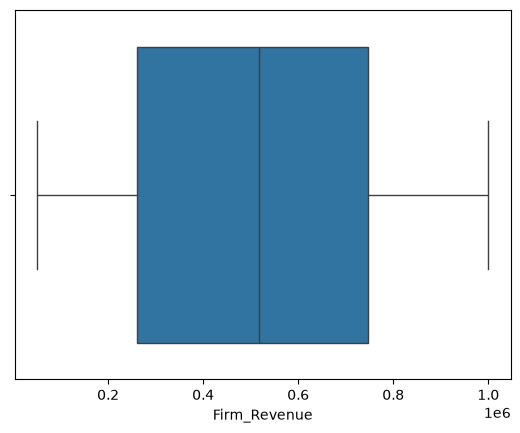

In [18]:
sns.boxplot(x=bank['Firm_Revenue'])
plt.show

In [19]:
bank['Firm_Revenue'].skew()

np.float64(0.03442049290109505)

In [21]:
#**Conclusion:** [Firm_revenue]
The column shows an approximately normal distribution with skewness close to 0, 
indicating that the data is relatively symmetric around the mean.
The box plot was also analyzed to identify potential outliers and assess the overall spread of the data.

SyntaxError: invalid syntax (1400117039.py, line 2)

In [22]:
bank['Firm_Revenue']= bank['Firm_Revenue'].fillna(bank['Firm_Revenue'].mean())

In [23]:
#filling of missing value using mean beacuse our data is not skewed!!
bank['Firm_Revenue'].isnull().sum()

np.int64(0)

In [24]:
#**cleaning of customer dataframe**
 
customer[customer['City'].isnull()]

,Customer_ID,Age,Customer_Type,City,Region,Bank_Name,Branch_ID
14,200014,41.0,Employee,NaN,North,HDFC Bank,1542
19,200019,20.0,Employee,NaN,North,HDFC Bank,1232
30,200030,50.0,Employee,NaN,North,HDFC Bank,1088
39,200039,76.0,Individual,NaN,South,HDFC Bank,1398
71,200071,19.0,Employee,NaN,North,HDFC Bank,1918
...,...,...,...,...,...,...,...
9894,209894,25.0,Business,NaN,South,HDFC Bank,1040
9916,209916,35.0,NaN,NaN,South,HDFC Bank,1748
9940,209940,36.0,Employee,NaN,West,HDFC Bank,1869
9951,209951,61.0,Individual,NaN,South,HDFC Bank,1906


In [25]:
print(customer.columns)
print(transaction.columns)
print(bank.columns)

Index(['Customer_ID', 'Age', 'Customer_Type', 'City', 'Region', 'Bank_Name',
       'Branch_ID'],
      dtype='str')
Index(['Transaction_ID', 'Customer_ID', 'Account_Type', 'Total_Balance',
       'Transaction_Amount', 'Investment_Amount', 'Investment_Type',
       'Transaction_Date'],
      dtype='str')
Index(['Branch_ID', 'City', 'Region', 'Firm_Revenue', 'Expenses',
       'Profit_Margin'],
      dtype='str')


In [26]:
customer[customer['Branch_ID'] == 1542]

,Customer_ID,Age,Customer_Type,City,Region,Bank_Name,Branch_ID
14,200014,41.0,Employee,NaN,North,HDFC Bank,1542
735,200735,46.0,Business,Pune,South,HDFC Bank,1542
3124,203124,25.0,Business,Kolhapur,North,HDFC Bank,1542
6236,206236,62.0,Employee,Pune,East,HDFC Bank,1542
7241,207241,41.0,Employee,Nagpur,North,HDFC Bank,1542
7477,207477,24.0,Business,Solapur,North,HDFC Bank,1542
8030,208030,69.0,Business,Kolhapur,North,HDFC Bank,1542
8059,208059,48.0,Employee,Mumbai,East,HDFC Bank,1542
8443,208443,26.0,NaN,Kolhapur,North,HDFC Bank,1542
8769,208769,46.0,NaN,Nagpur,East,HDFC Bank,1542


In [27]:
bank[bank['Branch_ID'] == 1542]

,Branch_ID,City,Region,Firm_Revenue,Expenses,Profit_Margin
542,1542,Nagpur,West,438639.0,76596,68.97


In [28]:
#filling city column using mode method
customer['City']=customer.groupby('Region')['City'].transform(
    lambda x: x.fillna(x.mode()[0] if not x.mode().empty else 'unknown')
)

In [29]:
customer['City'].isnull().sum()

np.int64(0)

In [30]:
customer[customer['Customer_Type'].isnull()]

,Customer_ID,Age,Customer_Type,City,Region,Bank_Name,Branch_ID
1,200001,69.0,NaN,Kolhapur,East,HDFC Bank,1648
28,200028,77.0,NaN,Solapur,North,HDFC Bank,1110
75,200075,77.0,NaN,Pune,West,HDFC Bank,1636
90,200090,23.0,NaN,Pune,West,HDFC Bank,1828
105,200105,65.0,NaN,Nagpur,West,HDFC Bank,1167
...,...,...,...,...,...,...,...
9934,209934,65.0,NaN,Solapur,North,HDFC Bank,1133
9936,209936,NaN,NaN,Pune,West,HDFC Bank,1174
9937,209937,47.0,NaN,Solapur,East,HDFC Bank,1260
9942,209942,20.0,NaN,Solapur,South,HDFC Bank,1886


In [31]:
customer['Customer_Type'].value_counts(dropna=False)

Customer_Type
Business      3186
Employee      3182
Individual    3132
NaN            500
Name: count, dtype: int64

In [32]:
pd.crosstab(
    customer['Region'],
    customer['Customer_Type']
)

Customer_Type,Business,Employee,Individual
Region,,,
East,775,857,772
North,799,789,803
South,748,757,759
West,864,779,798


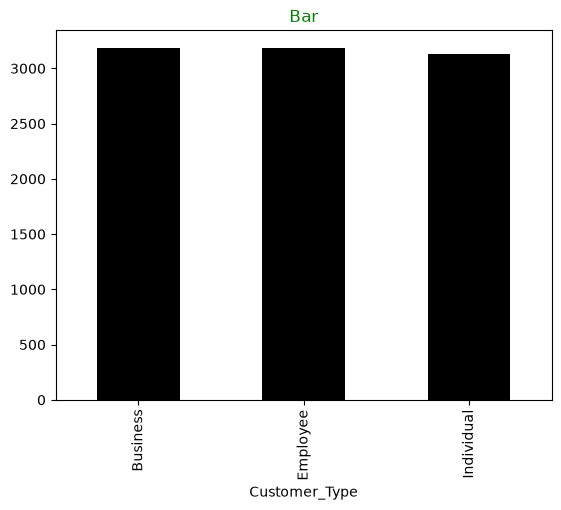

In [33]:
customer['Customer_Type'].value_counts().plot(kind='bar', color='black')

plt.title('Bar',color='green')
plt.show()

In [34]:
#filling missing values in customer type column
customer['Customer_Type']= customer.groupby('Region')['City'].transform(
    lambda x: x.fillna(x.mode()[0] if not x.mode().empty else 'unknown')
)

In [35]:
customer['Customer_Type'].isnull().sum()

np.int64(0)

In [36]:
customer['Age'].isnull().sum()

np.int64(500)

In [37]:
customer['Age'].dtype

dtype('float64')

In [38]:
customer['Age'].skew()


np.float64(-0.0012122369200941363)

In [39]:
customer['Age'].describe()

count    9500.000000
mean       48.754421
std        17.919179
min        18.000000
25%        33.000000
50%        49.000000
75%        64.000000
max        79.000000
Name: Age, dtype: float64

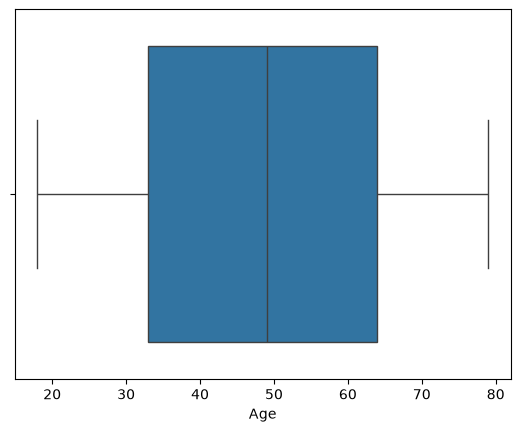

In [40]:
sns.boxplot(x=customer['Age'])
plt.show()

In [41]:
#filling missing values in Age column
customer['Age'] = customer['Age'].fillna(
    customer['Age'].mean()
)

In [42]:
customer.isnull().sum()

Customer_ID      0
Age              0
Customer_Type    0
City             0
Region           0
Bank_Name        0
Branch_ID        0
dtype: int64

In [43]:
bank.isnull().sum()

Branch_ID        0
City             0
Region           0
Firm_Revenue     0
Expenses         0
Profit_Margin    0
dtype: int64

In [46]:
transaction.isnull().sum()

Transaction_ID        0
Customer_ID           0
Account_Type          0
Total_Balance         0
Transaction_Amount    0
Investment_Amount     0
Investment_Type       0
Transaction_Date      0
dtype: int64

In [45]:
# now data is cleaned and i am going to make the new dataframe which is 


In [48]:
bank.to_csv(r"C:/Users/rakhi/OneDrive/Desktop/Data project/BFSI/bank_cleaned.csv", index=False)

customer.to_csv(r"C:/Users/rakhi/OneDrive/Desktop/Data project/BFSI/customer_cleaned.csv", index=False)

transaction.to_csv(r"C:/Users/rakhi/OneDrive/Desktop/Data project/BFSI/transaction_cleaned.csv", index=False)